In [91]:
from shape_plotting import plot_corner,plot_chain_evolution
import pickle
filename = '/home/bk639/MCMC-deprojection/Marvel.DC.results/all_galaxies.radius2.contained.False/bootstrap/all_galaxies_bootstrap.pkl'
# filename = '/home/bk639/MCMC-deprojection/Marvel.DC.results/all_galaxies.radius2.contained.False/all_galaxies_results.pkl'
with open(filename, 'rb') as f:
    data = pickle.load(f)


In [90]:
data.keys()

dict_keys(['samples', 'max_prob_params', 'full_chain', 'q_obs', 'a_obs', 'sampler'])

In [56]:
import numpy as np
bins = np.linspace(0,1,20)

In [96]:
mu_q, mu_s, sigma_q, sigma_s = [],[],[],[]
for i in range(len(data)):
    muq,mus,sb,sc = data['results'][i]['fit4']['map']
    mu_q.append(muq)
    mu_s.append(mus)
    sigma_q.append(sb)
    sigma_s.append(sc)
print(np.mean(mu_q), np.std(mu_q))
print(np.mean(mu_s), np.std(mu_s))

0.815595296391295 0.05533577051612226
0.36314137340013386 0.0294445033680881


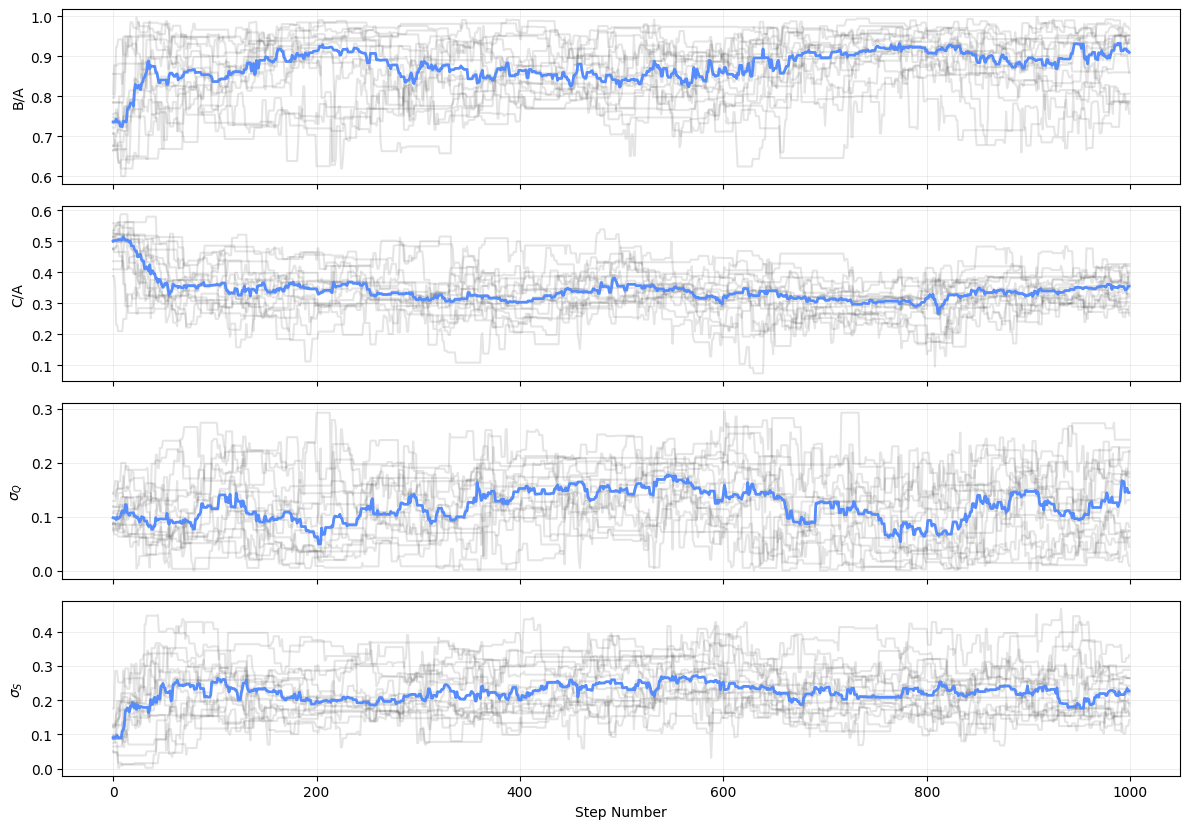

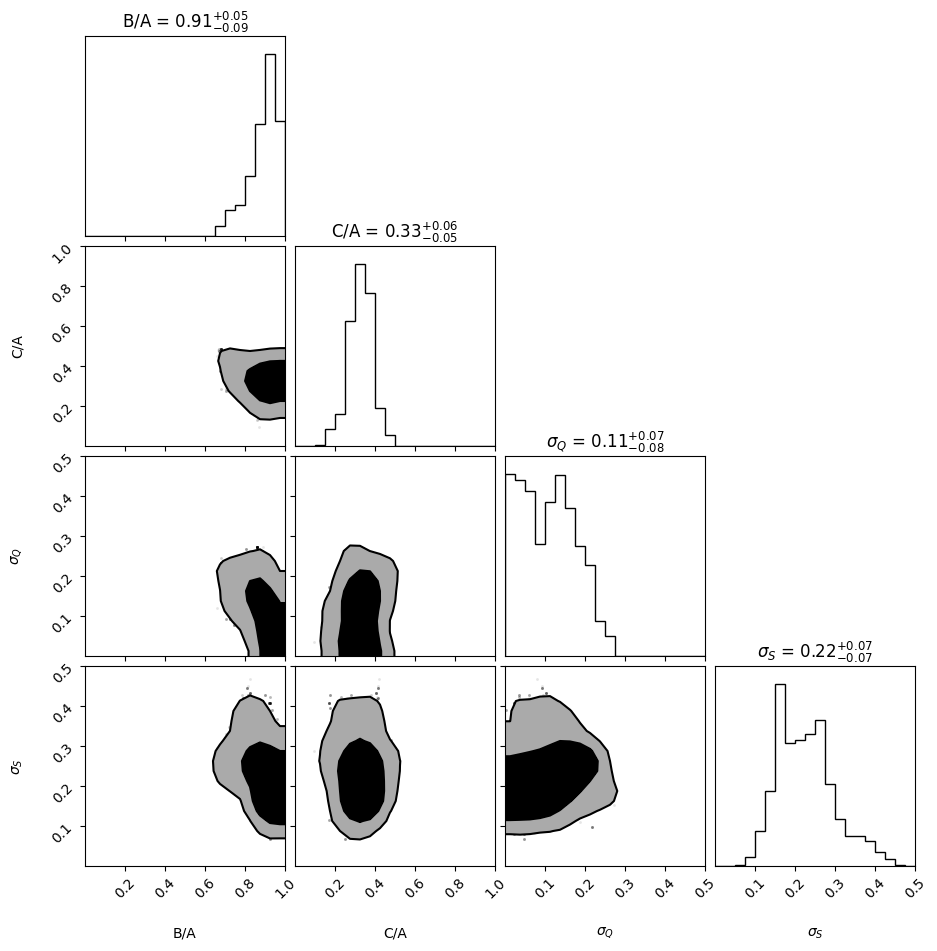

In [86]:
i = 1
sampler = (data['results'][i]['samp4'])
samples = data['results'][i]['s4']
from shape_inference import generate_model_projections
params = data['results'][i]['fit4']['map']

fig = plot_chain_evolution(sampler)
fig = plot_corner(samples)

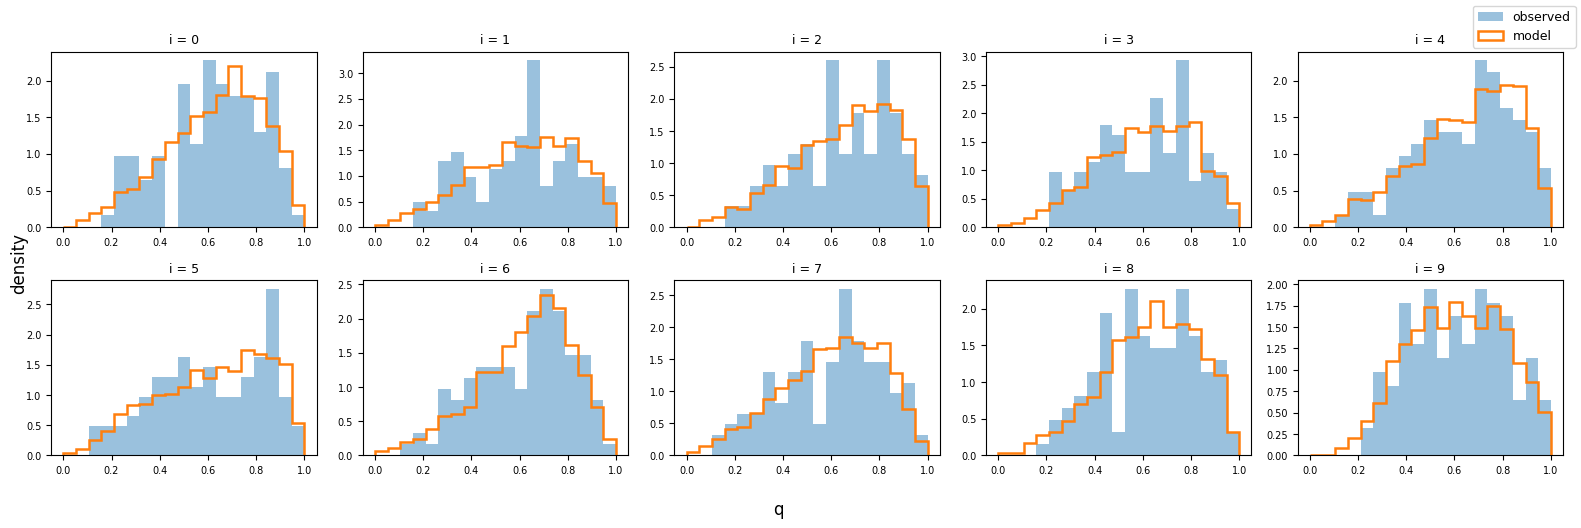

In [87]:
import numpy as np
import matplotlib.pyplot as plt
from shape_inference import generate_model_projections


def plot_hist_grid(data, start=0, n=20, ncols=5, nbins=25, n_proj=2000,
                   figsize_per_panel=(3.2, 2.6), save_as=None):
    """Plot observed q vs. model-projected q for results[start : start+n].

    Each panel gets its own shared bin edges (computed from both datasets
    together) so the two histograms are directly comparable, and both are
    normalized with density=True so differing sample counts don't distort
    the comparison.
    """
    results = data['results']
    idxs = range(start, min(start + n, len(results)))
    nrows = int(np.ceil(len(idxs) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
        squeeze=False,
    )
    axes = axes.ravel()

    for ax, i in zip(axes, idxs):
        res = results[i]
        obs = np.asarray(res['q'])
        params = res['fit4']['median']
        q_model, _, _ = generate_model_projections(params, n_proj)
        q_model = np.asarray(q_model)

        # One set of bin edges spanning both datasets
        Q_BINS = np.arange(0, 1.0000001, 0.08)

        ax.hist(obs.ravel(), bins=bins, density=True, histtype='stepfilled',
                alpha=0.45, color='tab:blue', label='observed')
        ax.hist(q_model.ravel(), bins=bins, density=True, histtype='step',
                linewidth=1.8, color='tab:orange', label='model')

        ax.set_title(f'i = {i}', fontsize=9)
        ax.tick_params(labelsize=7)

    # Hide unused panels
    for ax in axes[len(idxs):]:
        ax.set_visible(False)

    # Single legend for the whole figure
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', fontsize=9)
    fig.supxlabel('q')
    fig.supylabel('density')
    fig.tight_layout(rect=(0, 0, 1, 0.97))

    if save_as:
        fig.savefig(save_as, dpi=150)
    return fig


# --- Usage ---------------------------------------------------------------
# First 20:
plot_hist_grid(data, start=0, n=10)
plt.show()
#
# All 1000, 20 per figure (50 figures), saved to disk instead of shown:
#   for s in range(0, len(data['results']), 20):
#       fig = plot_hist_grid(data, start=s, n=20, save_as=f'hist_{s:04d}.png')
#       plt.close(fig)   # frees memory

In [8]:
print(data['results'].keys())

dict_keys([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99])


In [5]:
data['results'][0].keys()

dict_keys(['i', 'seed', 'q', 'a', 'error', 'fit4', 's4', 'm4', 'samp4', 'log_tail'])

In [51]:
Q_BINS = np.arange(0, 1.0000001, 0.04)

In [50]:
len(Q_BINS)

51